# Лабораторная работа №10. Otsu, k-means и метрики сегментации

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №10».

**Данные.** `data/seg_scene.png` и `data/seg_mask.png` — полусинтетическая сцена 640×480: фрагменты реальной фотографии апельсина (эллипс и прямоугольник) вставлены в реальную фотографию узорчатой ткани, добавлены неравномерное освещение и шум. Маска объекта при этом известна точно. Сцена собирается скриптом `prepare_data.py`.

> **Что нужно заменить перед сдачей.** Шаг 1 задания — *подготовить ground-truth маску* для своего изображения, то есть обвести объект вручную. Здесь маска получена построением сцены. Этого достаточно, чтобы проверить алгоритмы и метрики, но ошибки на настоящей фотографии с ручной разметкой будут другими.

## 1. О чём эта работа

### Знакомый пример

Кнопка «удалить фон» в редакторе фотографий или замена фона в видеозвонке. Программа должна про каждый пиксель решить: это объект или фон? Результат — чёрно-белая картинка-трафарет, **маска**.

### Основная идея

Два простых способа разделить пиксели на две группы без обучения.

1. **Порог.** Если объект темнее фона, выберем яркость $t$ и объявим объектом всё, что темнее. Вопрос — как выбрать $t$ автоматически. Оцу предложил: взять такой порог, при котором две получившиеся группы как можно сильнее отличаются друг от друга по средней яркости (и при этом каждая внутри как можно однороднее).
2. **Кластеризация.** Не выбирать порог, а найти два «типичных цвета» и отнести каждый пиксель к ближайшему. Алгоритм k-means находит эти типичные цвета сам.

А потом нужно **измерить**, насколько маска хороша, — сравнить её с эталонной и посчитать ошибки двух видов.

### Понятия

- **Ground truth (GT)** — эталонная маска, с которой сравнивают.
- **Класс** — группа пикселей (фон / объект). **Вес класса** $w$ — доля пикселей в нём. **Среднее класса** $\mu$ — их средняя яркость.
- **Between-class variance** (межклассовая дисперсия) $\sigma_B^2$ — насколько далеко друг от друга средние двух классов, с учётом их размеров.
- **Кластер** — группа похожих точек; **центр кластера** (центроид) — их среднее.
- **Objective** (целевая функция) $J$ k-means — сумма квадратов расстояний от точек до центров их кластеров. Чем меньше, тем компактнее кластеры.
- Четыре исхода для каждого пикселя:

| | в GT объект | в GT фон |
|---|---|---|
| **предсказан объект** | TP (верно) | FP (ложная тревога) |
| **предсказан фон** | FN (пропуск) | TN (верно) |

- **Precision** — какая доля предсказанного объекта действительно объект. **Recall** — какая доля настоящего объекта найдена.
- **IoU** (Intersection over Union) — площадь пересечения предсказанной и эталонной масок, делённая на площадь их объединения. **Dice** — похожая мера, более мягкая. Обе не учитывают TN — правильно угаданный фон.

### Формулы

Otsu — для каждого порога $t$:

$$\sigma_B^2(t)=w_0(t)\,w_1(t)\,[\mu_0(t)-\mu_1(t)]^2$$

$w_0,\mu_0$ — вес и среднее класса «яркость $\le t$», $w_1,\mu_1$ — класса «яркость $>t$». Выбирается $t$ с максимальным $\sigma_B^2$.

k-means:

$$J=\sum_i\|x_i-\mu_{c_i}\|^2$$

$x_i$ — точка, $c_i$ — номер её кластера, $\mu_{c_i}$ — центр этого кластера.

Метрики:

$$\mathrm{IoU}=\frac{TP}{TP+FP+FN},\quad \mathrm{Dice}=\frac{2TP}{2TP+FP+FN},\quad \mathrm{Precision}=\frac{TP}{TP+FP},\quad \mathrm{Recall}=\frac{TP}{TP+FN}$$

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

SCENE, MASK = "data/seg_scene.png", "data/seg_mask.png"
FIXED_THRESHOLD = 127
GRABCUT_RECT = (100, 70, 420, 320)      # x, y, w, h — грубая рамка вокруг объекта
SEED = 0
rng = np.random.default_rng(SEED)

## 2. Вопрос 1 — Otsu вручную

> Для counts=[4,1,1,4] по уровням 0,1,2,3 сравните Otsu thresholds t=0,1,2 и выберите максимум between-class variance.

Всего пикселей $N=10$, вероятности $p=[0.4,\ 0.1,\ 0.1,\ 0.4]$. Порог $t$ делит уровни на класс 0 (уровни $\le t$) и класс 1 (уровни $>t$).

**t = 0.** Класс 0: только уровень 0. $w_0=0.4$, $\mu_0=0$. Класс 1: уровни 1, 2, 3 с числом пикселей 1, 1, 4. $w_1=0.6$, $\mu_1=\frac{1\cdot1+2\cdot1+3\cdot4}{6}=\frac{15}{6}=2.5$.

$$\sigma_B^2=0.4\cdot0.6\cdot(0-2.5)^2=0.24\cdot6.25=1.5$$

**t = 1.** Класс 0: уровни 0 и 1 (4 и 1 пиксель). $w_0=0.5$, $\mu_0=\frac{0\cdot4+1\cdot1}{5}=0.2$. Класс 1: уровни 2 и 3 (1 и 4 пикселя). $w_1=0.5$, $\mu_1=\frac{2\cdot1+3\cdot4}{5}=2.8$.

$$\sigma_B^2=0.5\cdot0.5\cdot(0.2-2.8)^2=0.25\cdot6.76=1.69$$

**t = 2.** Гистограмма симметрична, поэтому случай зеркален $t=0$: $w_0=0.6$, $\mu_0=0.5$, $w_1=0.4$, $\mu_1=3$; $\sigma_B^2=0.24\cdot6.25=1.5$.

**Максимум при $t=1$** ($1.69>1.5$).

**Смысл.** Гистограмма — два «горба» по краям (уровни 0 и 3) и редкие значения между ними. Лучший порог проходит посередине, между горбами. При $t=0$ или $t=2$ один из горбов делит класс с промежуточными уровнями — классы получаются менее однородными.

In [2]:
def otsu_table(counts):
    """σ_B²(t) для всех порогов t: класс 0 — уровни ≤ t, класс 1 — уровни > t."""
    p = np.asarray(counts, dtype=np.float64); p = p / p.sum()
    levels = np.arange(len(p))
    w0 = np.cumsum(p)                       # вес класса 0 для каждого t
    w1 = 1 - w0
    m = np.cumsum(p * levels)               # накопленная сумма p·уровень
    mu_total = m[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        mu0 = m / w0
        mu1 = (mu_total - m) / w1
        sigma_b = w0 * w1 * (mu0 - mu1) ** 2
    sigma_b[~np.isfinite(sigma_b)] = 0      # если один из классов пуст
    return w0, w1, mu0, mu1, sigma_b

w0, w1, mu0, mu1, sb = otsu_table([4, 1, 1, 4])
print(f"{'t':>2}{'w0':>6}{'μ0':>7}{'w1':>6}{'μ1':>7}{'σ_B²':>8}")
for t in range(3):
    print(f"{t:2d}{w0[t]:6.2f}{mu0[t]:7.3f}{w1[t]:6.2f}{mu1[t]:7.3f}{sb[t]:8.3f}")
print("лучший порог:", int(np.argmax(sb)))

 t    w0     μ0    w1     μ1    σ_B²
 0  0.40  0.000  0.60  2.500   1.500
 1  0.50  0.200  0.50  2.800   1.690
 2  0.60  0.500  0.40  3.000   1.500
лучший порог: 1


**Итог вопроса 1:** $\sigma_B^2=1.5,\ 1.69,\ 1.5$; лучший порог $t=1$.

## 3. Вопрос 2 — k-means вручную

> Для данных [1,2,4,10,11,13], c1=2, c2=11 выполните две итерации k-means и посчитайте итоговый objective J. Объясните роль initialization.

Одна итерация — два шага: **assignment** (каждую точку отнести к ближайшему центру) и **update** (каждый центр переставить в среднее своих точек).

**Итерация 1, assignment.** Расстояния до $c_1=2$ и $c_2=11$:

| точка | до $c_1$ | до $c_2$ | кластер |
|---|---|---|---|
| 1 | 1 | 10 | 1 |
| 2 | 0 | 9 | 1 |
| 4 | 2 | 7 | 1 |
| 10 | 8 | 1 | 2 |
| 11 | 9 | 0 | 2 |
| 13 | 11 | 2 | 2 |

Кластеры: $\{1,2,4\}$ и $\{10,11,13\}$.

**Итерация 1, update.** $c_1=(1+2+4)/3=7/3\approx2.333$; $c_2=(10+11+13)/3=34/3\approx11.333$.

**Итерация 2, assignment.** Граница между кластерами — середина между центрами: $(2.333+11.333)/2=6.833$. Точки 1, 2, 4 слева, 10, 11, 13 справа — состав не изменился.

**Итерация 2, update.** Состав тот же, значит и центры те же. Алгоритм **сошёлся**.

**Objective.**

$$J=(1-2.333)^2+(2-2.333)^2+(4-2.333)^2+(10-11.333)^2+(11-11.333)^2+(13-11.333)^2$$
$$=1.778+0.111+2.778+1.778+0.111+2.778=9.333$$

Оба кластера имеют одинаковую форму (отклонения $-\frac43,-\frac13,+\frac53$), поэтому вклад каждого $\frac{42}{9}=4.667$.

### Роль initialization

Каждый шаг k-means не увеличивает $J$: assignment выбирает ближайший центр, update ставит центр в среднее (а среднее минимизирует сумму квадратов расстояний). Поэтому алгоритм всегда сходится — но к **локальному** минимуму: состоянию, которое нельзя улучшить одним шагом, хотя существует другое разбиение с меньшим $J$. Какой минимум будет найден, зависит от стартовых центров. В нашем примере два кластера очевидны, и почти любой старт приводит к одному ответу. Пример, где это не так, — в разделе 5.

In [3]:
def kmeans(X, centers, max_iter=100, tol=1e-6, verbose=False):
    """k-means: assignment по квадрату расстояния, update средними, остановка при малом сдвиге центров."""
    X = np.asarray(X, dtype=np.float64)
    if X.ndim == 1: X = X[:, None]
    centers = np.asarray(centers, dtype=np.float64).reshape(len(centers), -1).copy()
    for it in range(1, max_iter + 1):
        d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)       # N×k
        labels = d2.argmin(axis=1)                                          # assignment
        new = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centers[j] for j in range(len(centers))])
        shift = np.abs(new - centers).max()
        centers = new                                                       # update
        J = ((X - centers[labels]) ** 2).sum()
        if verbose:
            print(f"  итерация {it}: центры = {centers.ravel()}, J = {J:.4f}, кластеры = {[X[labels == j].ravel().tolist() for j in range(len(centers))]}")
        if shift < tol:
            break
    return centers, labels, J, it

data = np.array([1.0, 2, 4, 10, 11, 13])
c, lab, J, n_it = kmeans(data, [2.0, 11.0], max_iter=2, verbose=True)
print("центры:", c.ravel(), " J =", round(J, 4), " = 28/3 =", round(28 / 3, 4))

  итерация 1: центры = [ 2.3333 11.3333], J = 9.3333, кластеры = [[1.0, 2.0, 4.0], [10.0, 11.0, 13.0]]
  итерация 2: центры = [ 2.3333 11.3333], J = 9.3333, кластеры = [[1.0, 2.0, 4.0], [10.0, 11.0, 13.0]]
центры: [ 2.3333 11.3333]  J = 9.3333  = 28/3 = 9.3333


**Итог вопроса 2:** $c_1\approx2.333$, $c_2\approx11.333$, $J\approx9.333$.

## 4. Задание 3 — код и эксперимент

### Шаги 1–2. Изображение, ground truth, гистограмма

размер: (480, 640)  доля объекта в GT: 0.1859
средняя яркость: объект 114.0, фон 167.1 → объект темнее фона


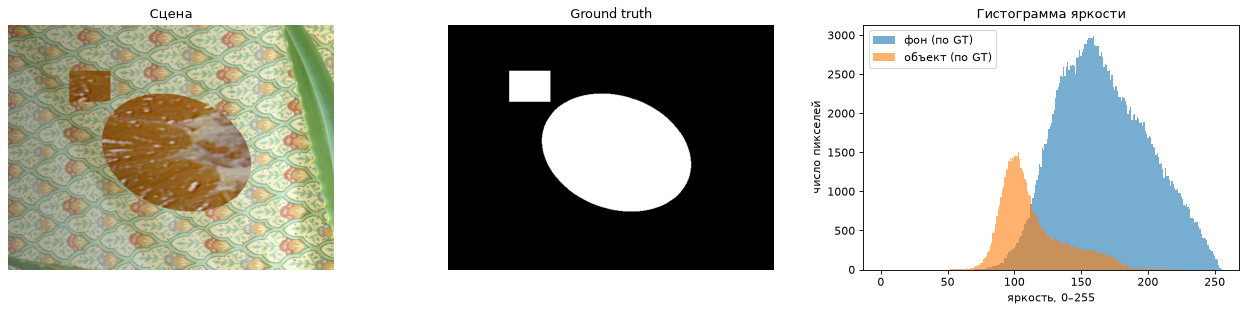

In [4]:
scene = cv2.imread(SCENE); gt = cv2.imread(MASK, cv2.IMREAD_GRAYSCALE) > 0
gray = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)
assert scene.shape[:2] == gt.shape
print("размер:", gray.shape, " доля объекта в GT:", round(gt.mean(), 4))
print(f"средняя яркость: объект {gray[gt].mean():.1f}, фон {gray[~gt].mean():.1f} → объект темнее фона")

hist = np.bincount(gray.ravel(), minlength=256)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(scene[..., ::-1]); ax[0].set_title("Сцена"); ax[0].axis("off")
ax[1].imshow(gt); ax[1].set_title("Ground truth"); ax[1].axis("off")
ax[2].bar(np.arange(256), np.bincount(gray[~gt], minlength=256), width=1, color="tab:blue", alpha=0.6, label="фон (по GT)")
ax[2].bar(np.arange(256), np.bincount(gray[gt], minlength=256), width=1, color="tab:orange", alpha=0.6, label="объект (по GT)")
ax[2].set(title="Гистограмма яркости", xlabel="яркость, 0–255", ylabel="число пикселей"); ax[2].legend()
plt.tight_layout(); plt.show()

Гистограмма раскрашена по GT, чтобы было видно, насколько задача решаема порогом: распределения объекта и фона **перекрываются**. Никакой порог не разделит их без ошибок.

### Шаги 3–4. Собственный Otsu и сравнение с OpenCV

Та же функция `otsu_table`, что решала вопрос 1, применяется к гистограмме из 256 уровней.

порог Otsu: свой = 159, OpenCV = 159
при t=159: w0=0.537, μ0=128.2, w1=0.463, μ1=191.0, σ_B²=978.8


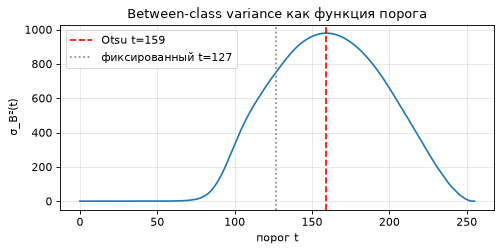

In [5]:
w0, w1, mu0, mu1, sb = otsu_table(hist)
t_mine = int(np.argmax(sb))
t_cv, _ = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"порог Otsu: свой = {t_mine}, OpenCV = {int(t_cv)}")
print(f"при t={t_mine}: w0={w0[t_mine]:.3f}, μ0={mu0[t_mine]:.1f}, w1={w1[t_mine]:.3f}, μ1={mu1[t_mine]:.1f}, σ_B²={sb[t_mine]:.1f}")

plt.figure(figsize=(7, 3))
plt.plot(sb); plt.axvline(t_mine, color="r", ls="--", label=f"Otsu t={t_mine}"); plt.axvline(FIXED_THRESHOLD, color="gray", ls=":", label=f"фиксированный t={FIXED_THRESHOLD}")
plt.title("Between-class variance как функция порога"); plt.xlabel("порог t"); plt.ylabel("σ_B²(t)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Шаги 5–7. Собственный k-means

Функция `kmeans` уже проверена на одномерной задаче вопроса 2 (шаг 6). Применяем её к изображению двумя способами:

- **по яркости** (1 признак на пиксель) — тогда это прямой конкурент Otsu;
- **по цвету в пространстве Lab** (3 признака). Lab устроено так, что евклидово расстояние между цветами примерно соответствует воспринимаемой разнице: $L$ — светлота, $a$ — ось «зелёный–красный», $b$ — ось «синий–жёлтый»;
- **только по цветности $(a,b)$** (2 признака, без светлоты). Освещение меняет в основном $L$, а оттенок остаётся в $a$ и $b$.

Начальные центры — два случайных пикселя (seed зафиксирован), одни и те же для всех трёх вариантов. Какой из двух кластеров объявить объектом, алгоритм не знает; используем априорное знание: по яркости — более тёмный, по цвету — более «красный» (большее $a$).

In [6]:
lab_img = cv2.cvtColor(scene, cv2.COLOR_BGR2LAB).astype(np.float64)
X_gray = gray.reshape(-1, 1).astype(np.float64)
X_lab = lab_img.reshape(-1, 3)

init_idx = rng.choice(len(X_gray), size=2, replace=False)
cg, lg, Jg, itg = kmeans(X_gray, X_gray[init_idx])
cl, ll, Jl, itl = kmeans(X_lab, X_lab[init_idx])
X_ab = X_lab[:, 1:]                                                         # только цветность, без светлоты L
cab, lab_ab, Jab, itab = kmeans(X_ab, X_ab[init_idx])
print(f"k-means по яркости: центры {cg.ravel()}, итераций {itg}; граница между кластерами = {cg.mean():.1f} (Otsu: {t_mine})")
print(f"k-means по Lab    : центры\n{cl}\n  итераций {itl}")
print(f"k-means по (a, b) : центры\n{cab}\n  итераций {itab}")
print("разброс (std) каналов L, a, b по кадру:", X_lab.std(axis=0))

pred_kmeans_gray = (lg == np.argmin(cg.ravel())).reshape(gray.shape)        # более тёмный кластер
pred_kmeans_lab = (ll == np.argmax(cl[:, 1])).reshape(gray.shape)           # кластер с большим a (краснее)
pred_kmeans_ab = (lab_ab == np.argmax(cab[:, 0])).reshape(gray.shape)

k-means по яркости: центры [128.8107 191.6642], итераций 9; граница между кластерами = 160.2 (Otsu: 159)
k-means по Lab    : центры
[[137.1095 127.4027 151.9835]
 [197.0888 119.7586 145.7319]]
  итераций 27
k-means по (a, b) : центры
[[118.9377 144.8376]
 [139.5558 162.691 ]]
  итераций 17
разброс (std) каналов L, a, b по кадру: [36.6546 11.7952 11.0757]


Посмотрите на центры k-means по Lab: они различаются почти только по $L$ (137 и 197), а по $a$ и $b$ — на считаные единицы. Разброс $L$ по кадру втрое больше разброса цветности (std ≈ 37 против ≈ 12), и квадрат расстояния в k-means почти целиком определяется светлотой. Алгоритм нашёл не «апельсин и ткань», а «тёмное и светлое». Вариант без $L$ вынужден делить по оттенку.

Граница между кластерами одномерного k-means практически совпала с порогом Otsu. Это не случайность: максимизировать межклассовую дисперсию — то же самое, что минимизировать внутриклассовую (их сумма — полная дисперсия, а она постоянна), а внутриклассовая дисперсия — это и есть $J$ k-means для двух кластеров. Otsu находит глобальный оптимум перебором 256 порогов, k-means приходит к нему итерациями.

### Шаг 8. Маски всех методов

Методы: фиксированный порог, Otsu, k-means (три варианта) и **GrabCut** из OpenCV. GrabCut получает грубую рамку вокруг объекта и считает всё вне рамки фоном; внутри он строит цветовые модели объекта и фона и ищет границу, проходящую по перепадам цвета. Это метод другого класса: он использует и цвет, и соседство пикселей, и подсказку пользователя.

In [7]:
pred_fixed = gray < FIXED_THRESHOLD
pred_otsu = gray <= t_mine

gc_mask = np.zeros(gray.shape, np.uint8)
cv2.setRNGSeed(SEED)
cv2.grabCut(scene, gc_mask, GRABCUT_RECT, np.zeros((1, 65)), np.zeros((1, 65)), 5, cv2.GC_INIT_WITH_RECT)
pred_grabcut = (gc_mask == cv2.GC_FGD) | (gc_mask == cv2.GC_PR_FGD)

preds = {
    f"threshold {FIXED_THRESHOLD}": pred_fixed,
    f"Otsu (t={t_mine})": pred_otsu,
    "k-means gray": pred_kmeans_gray,
    "k-means Lab": pred_kmeans_lab,
    "k-means ab": pred_kmeans_ab,
    "GrabCut": pred_grabcut,
}

### Шаг 9. Собственный расчёт TP, FP, FN, TN и метрик

In [8]:
def mask_metrics(pred, gt):
    pred = pred.astype(bool); gt = gt.astype(bool)
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()
    tn = np.logical_and(~pred, ~gt).sum()
    eps = 1e-12
    return dict(tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
                iou=tp / (tp + fp + fn + eps), dice=2 * tp / (2 * tp + fp + fn + eps),
                precision=tp / (tp + fp + eps), recall=tp / (tp + fn + eps),
                accuracy=(tp + tn) / (tp + fp + fn + tn))

# самопроверка на масках, где ответ известен
a = np.array([[1, 1, 0, 0]], bool); b_ = np.array([[1, 0, 1, 0]], bool)
m = mask_metrics(a, b_); assert (m["tp"], m["fp"], m["fn"], m["tn"]) == (1, 1, 1, 1) and np.isclose(m["iou"], 1 / 3) and np.isclose(m["dice"], 0.5)

print(f"{'Метод':18}{'TP':>8}{'FP':>8}{'FN':>8}{'TN':>8}{'IoU':>8}{'Dice':>8}{'Precision':>11}{'Recall':>8}{'Accuracy':>10}")
metrics = {}
for name, pr in preds.items():
    m = metrics[name] = mask_metrics(pr, gt)
    print(f"{name:18}{m['tp']:8d}{m['fp']:8d}{m['fn']:8d}{m['tn']:8d}{m['iou']:8.3f}{m['dice']:8.3f}{m['precision']:11.3f}{m['recall']:8.3f}{m['accuracy']:10.3f}")
m = mask_metrics(np.zeros_like(gt), gt)
print(f"{'«всё — фон»':18}{m['tp']:8d}{m['fp']:8d}{m['fn']:8d}{m['tn']:8d}{m['iou']:8.3f}{m['dice']:8.3f}{m['precision']:11.3f}{m['recall']:8.3f}{m['accuracy']:10.3f}")

Метод                   TP      FP      FN      TN     IoU    Dice  Precision  Recall  Accuracy
threshold 127        42725   27248   14380  222847   0.507   0.672      0.611   0.748     0.864
Otsu (t=159)         52939  112146    4166  137949   0.313   0.477      0.321   0.927     0.621
k-means gray         53188  115022    3917  135073   0.309   0.472      0.316   0.931     0.613
k-means Lab          52892  100510    4213  149585   0.336   0.503      0.345   0.926     0.659
k-means ab           45746   23358   11359  226737   0.569   0.725      0.662   0.801     0.887
GrabCut              57077       5      28  250090   0.999   1.000      1.000   1.000     1.000
«всё — фон»              0       0   57105  250095   0.000   0.000      0.000   0.000     0.814


Последняя строка — «метод», который вообще ничего не находит. Его accuracy всё равно высокая: фон занимает большую часть кадра, и «всё — фон» угадывает большинство пикселей. IoU и Dice при этом равны нулю.

### Шаг 10. Цветовая карта ошибок

Зелёный — TP (объект найден), красный — FP (фон принят за объект), синий — FN (объект пропущен), чёрный — TN.

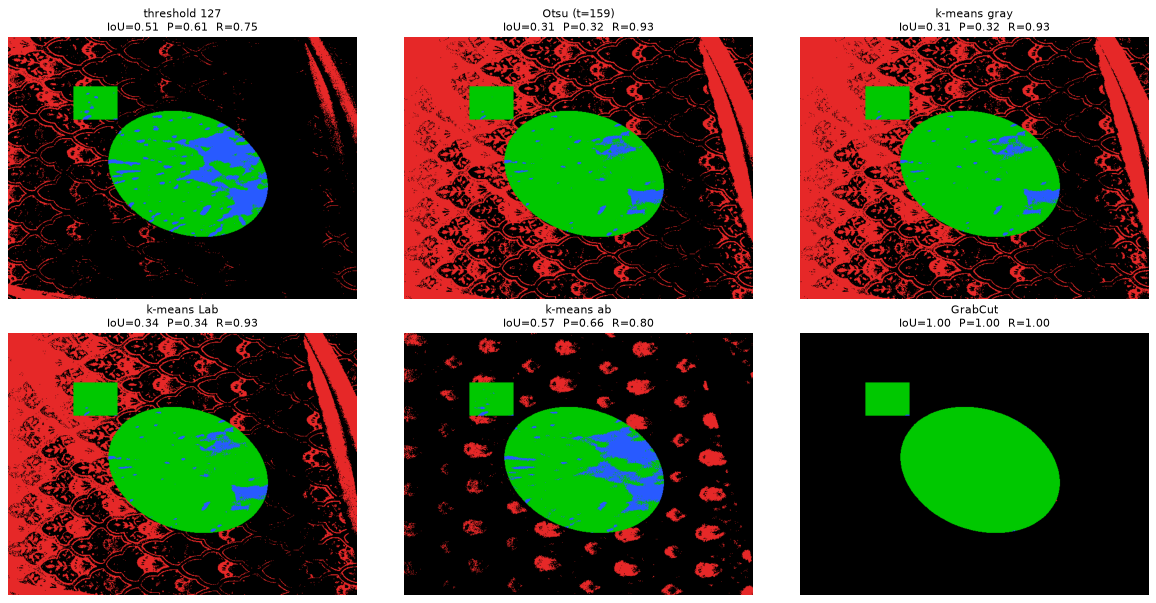

Метод               FP слева  FP справа  FN слева  FN справа
threshold 127          20738       6510      2300      12080
Otsu (t=159)           82141      30005       517       3649
k-means gray           84137      30885       487       3430
k-means Lab            74686      25824       491       3722
k-means ab              9795      13563      1204      10155
GrabCut                    0          5        15         13


In [9]:
def error_map(pred, gt):
    out = np.zeros(gt.shape + (3,), np.uint8)
    out[pred & gt] = (0, 200, 0)
    out[pred & ~gt] = (230, 40, 40)
    out[~pred & gt] = (40, 90, 255)
    return out

fig, ax = plt.subplots(2, 3, figsize=(15, 7.6)); ax = ax.ravel()
for a_, (name, pr) in zip(ax, preds.items()):
    a_.imshow(error_map(pr, gt)); a_.set_title(f"{name}\nIoU={metrics[name]['iou']:.2f}  P={metrics[name]['precision']:.2f}  R={metrics[name]['recall']:.2f}", fontsize=10); a_.axis("off")
plt.tight_layout(); plt.show()

# где сосредоточены ошибки: левая (затемнённая) и правая (светлая) половины кадра
Wm = gt.shape[1]
print(f"{'Метод':18}{'FP слева':>10}{'FP справа':>11}{'FN слева':>10}{'FN справа':>11}")
for name, pr in preds.items():
    fp, fn = pr & ~gt, ~pr & gt
    print(f"{name:18}{int(fp[:, :Wm // 2].sum()):10d}{int(fp[:, Wm // 2:].sum()):11d}{int(fn[:, :Wm // 2].sum()):10d}{int(fn[:, Wm // 2:].sum()):11d}")

## 5. Неудачные случаи

### k-means и плохая инициализация

Одномерные данные из трёх очевидных групп: около 0, около 10 и около 20. Запустим k-means с $k=3$ из двух стартов.

In [10]:
d3 = np.array([0.0, 1, 10, 11, 20, 21])
print("хороший старт (по центру на группу):")
c_good, _, J_good, _ = kmeans(d3, [0.0, 10.0, 20.0], verbose=True)
print("плохой старт (два центра в одной группе):")
c_bad, _, J_bad, _ = kmeans(d3, [0.0, 1.0, 10.0], verbose=True)
print(f"J: хороший старт = {J_good:.2f}, плохой старт = {J_bad:.2f} — в {J_bad / J_good:.0f} раз хуже, и алгоритм считает, что сошёлся")

# то же на изображении: 20 случайных стартов k-means по Lab
Js, ious = [], []
for s in range(20):
    r = np.random.default_rng(s)
    cc, lbl, Jx, _ = kmeans(X_lab[::16], X_lab[r.choice(len(X_lab), 2, replace=False)])
    pr = (((X_lab[:, None, :] - cc[None]) ** 2).sum(2).argmin(1) == np.argmax(cc[:, 1])).reshape(gray.shape)
    Js.append(Jx); ious.append(mask_metrics(pr, gt)["iou"])
print(f"\nизображение, k=2, 20 случайных стартов: IoU от {min(ious):.3f} до {max(ious):.3f}, различных значений J: {len(set(np.round(Js, -3)))}")

хороший старт (по центру на группу):
  итерация 1: центры = [ 0.5 10.5 20.5], J = 1.5000, кластеры = [[0.0, 1.0], [10.0, 11.0], [20.0, 21.0]]
  итерация 2: центры = [ 0.5 10.5 20.5], J = 1.5000, кластеры = [[0.0, 1.0], [10.0, 11.0], [20.0, 21.0]]
плохой старт (два центра в одной группе):
  итерация 1: центры = [ 0.   1.  15.5], J = 101.0000, кластеры = [[0.0], [1.0], [10.0, 11.0, 20.0, 21.0]]
  итерация 2: центры = [ 0.   1.  15.5], J = 101.0000, кластеры = [[0.0], [1.0], [10.0, 11.0, 20.0, 21.0]]
J: хороший старт = 1.50, плохой старт = 101.00 — в 67 раз хуже, и алгоритм считает, что сошёлся



изображение, k=2, 20 случайных стартов: IoU от 0.337 до 0.338, различных значений J: 1


При плохом старте два центра «делят» одну группу из двух точек, а третьему достаются сразу две далёкие группы. Ни один шаг не может это исправить: точка 10 ближе к центру 15.5, чем к центру 1, и переходить не станет. Алгоритм остановился в локальном минимуме. Лечение — несколько запусков с разными стартами и выбор варианта с наименьшим $J$, либо инициализация k-means++ (центры выбираются далеко друг от друга).

Для изображения с $k=2$ результат от старта практически не зависит: два кластера — слишком простая задача.

### Три характерные ошибки на картах шага 10

1. **Затемнённая левая часть кадра и лист алоэ справа — FP у всех методов по яркости.** Сцена освещена неравномерно: слева темнее. Глобальный порог один на весь кадр, и в левой части ткань оказывается темнее порога. У Otsu 82 тысячи ложных пикселей слева против 30 тысяч справа. Otsu здесь хуже фиксированного порога 127 (IoU 0.31 против 0.51): гистограмма не двугорбая, и максимум межклассовой дисперсии достигается при пороге 159, который делит кадр на «тёмную половину» и «светлую половину», а не на объект и фон. Otsu оптимален по своему критерию — но критерий не знает, что такое объект.
2. **Светлая мякоть в правой части эллипса — FN.** Белые перегородки апельсина светлее порога и не оранжевые по цвету. Их пропускают и пороговые методы, и k-means по цветности: по своим признакам эти пиксели действительно ближе к фону. У k-means по $(a,b)$ это главная ошибка (11 тысяч FN).
3. **Красные цветы узора ткани — FP у k-means по цветности.** Отказ от светлоты убрал зависимость от освещения (FP слева и справа примерно поровну: 9.8 и 13.6 тысячи), но цветы на ткани имеют тот же оттенок, что апельсин. Кластеризация по цвету не отличает «объект» от «другого предмета того же цвета».

## 6. Вывод

- **Ручные расчёты** совпали с кодом: Otsu выбирает $t=1$ ($\sigma_B^2=1.69$ против 1.5); k-means сходится за две итерации к центрам 2.333 и 11.333, $J=9.333$.
- **Проверка реализаций.** Собственный порог Otsu равен 159 — как у `cv2.threshold(..., THRESH_OTSU)`. Граница одномерного k-means — 160.2: оба метода минимизируют внутриклассовую дисперсию.
- **Сравнение методов:**

| Метод | IoU | Dice | Precision | Recall | Характер ошибок |
|---|---|---|---|---|---|
| threshold 127 | 0.507 | 0.672 | 0.611 | 0.748 | умеренные FP слева, пропуск светлой мякоти |
| Otsu (t=159) | 0.313 | 0.477 | 0.321 | 0.927 | почти весь объект найден, но две трети «объекта» — фон |
| k-means gray | 0.309 | 0.472 | 0.316 | 0.931 | то же, что Otsu |
| k-means Lab | 0.336 | 0.503 | 0.345 | 0.926 | то же: кластеры различаются светлотой |
| k-means ab | 0.569 | 0.725 | 0.662 | 0.801 | FP на красных цветах ткани, FN на мякоти |
| GrabCut | 0.999 | 1.000 | 1.000 | 1.000 | — |

- **Высокий recall не означает хорошую маску.** У Otsu recall 0.93 — объект почти не пропущен, — но precision 0.32: маска втрое больше объекта. Фиксированный порог 127 находит меньше (recall 0.75), зато чище. Какой вариант лучше, зависит от задачи: если пропуск дорог — первый, если ложная тревога — второй. IoU и Dice штрафуют оба вида ошибок.
- **Выбор признаков важнее выбора алгоритма.** Один и тот же k-means даёт IoU 0.31 по яркости, 0.34 по Lab и 0.57 по цветности. Добавление «лишнего» признака $L$ с большим разбросом не помогло, а почти полностью определило результат.
- **GrabCut** дал практически идеальную маску. Здесь это не показатель: объект вставлен в сцену с резкой границей, а алгоритму дана рамка. На настоящей фотографии с мягкими границами и похожими цветами фона результат будет хуже.
- **Accuracy обманчива:** «метод», объявляющий весь кадр фоном, получает accuracy 0.814 при IoU = 0 — выше, чем Otsu (0.621), который объект нашёл.
- **Локальные минимумы k-means:** на трёх группах при неудачном старте $J=101$ вместо 1.5, при этом алгоритм «сошёлся». На изображении с $k=2$ двадцать случайных стартов дали один и тот же результат.
- **Ограничение эксперимента:** сцена составная, маска точная по построению. По условию нужно своё изображение с ручной разметкой.

## 7. Вопросы на защиту

**1. Почему Otsu можно рассматривать как задачу одномерной оптимизации?**
Потому что единственная неизвестная — порог $t$, целое число от 0 до 255, а критерий $\sigma_B^2(t)$ — функция одного этого числа. Гистограмма сжимает всё изображение до 256 чисел, и оптимум находится полным перебором 256 значений; с накопленными суммами (`cumsum`) каждое значение считается за $O(1)$.

**2. Почему k-means может зависеть от начальных centers и что минимизирует его objective?**
$J$ — сумма квадратов расстояний от точек до центров их кластеров (внутрикластерный разброс). Оба шага алгоритма не увеличивают $J$, поэтому он сходится, но $J$ как функция одновременно центров и назначений невыпукла и имеет много локальных минимумов. Алгоритм — локальный спуск: он приходит в ближайший минимум от стартовой точки. Пример — раздел 5.

**3. Собственный расчёт TP/FP/FN; почему accuracy может быть высокой при плохой сегментации.**
В `mask_metrics`: `pred & gt` — TP, `pred & ~gt` — FP, `~pred & gt` — FN, `~pred & ~gt` — TN; `.sum()` считает пиксели. Accuracy $=(TP+TN)/N$ включает TN. Если объект занимает малую долю кадра, TN огромно, и accuracy близка к 1 даже при $TP=0$ (строка «всё — фон» в таблице). IoU и Dice не содержат TN и потому отражают качество именно на объекте.